# House Prices Prediction - Version 2

**Improvement idea: combine Ridge and Gradient Boosting, and evaluate them with five-fold cross-validation.**

- Keep V1's cleaning rules and six engineered features to focus this experiment on modeling.
- Ridge learns linear relationships. Gradient Boosting uses shallow trees to capture non-linear relationships and interactions. Their errors may complement each other.
- Use a fixed blend: **50% Ridge + 50% Gradient Boosting**, calculated on log-price predictions. Do not tune the weights on the validation results.
- Use the same five folds for both models and the blend. Learn medians, modes, dummy columns, and scaling inside each training fold. Compare out-of-fold (OOF) log-RMSE, fold variability, and fitting time.
- V1's 0.123827 came from one 80/20 split. Compare V2's blend against the Ridge baseline rerun on the same five folds, rather than comparing these different validation settings directly.
- The submission uses the equal blend. Check the results before uploading: combining models does not guarantee improvement. Refit both models on all 1,460 training rows and predict all 1,459 test rows.




In [1]:
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

sns.set_theme(style="whitegrid")


In [2]:
data_dir = Path("Dataset")
if not data_dir.exists():
    data_dir = Path("Proj/Dataset")
if not data_dir.exists():
    data_dir = Path("/kaggle/input/house-prices-advanced-regression-techniques")

train = pd.read_csv(data_dir / "train.csv", keep_default_na=False, na_values=["", "NA"])
test = pd.read_csv(data_dir / "test.csv", keep_default_na=False, na_values=["", "NA"])

print("Train:", train.shape)
print("Test:", test.shape)
train.head()


Train: (1460, 81)
Test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
y = np.log(train["SalePrice"])
test_ids = test["Id"].copy()

train_features = train.drop(columns=["Id", "SalePrice"])
test_features = test.drop(columns="Id")
data = pd.concat([train_features, test_features], ignore_index=True)


In [4]:
none_columns = ["Alley", "Fence", "MiscFeature", "PoolQC", "FireplaceQu",
                "GarageType", "GarageFinish", "GarageQual", "GarageCond",
                "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
for col in none_columns:
    data[col] = data[col].fillna("None")

data["MasVnrType"] = data["MasVnrType"].fillna("Unknown")

zero_columns = ["GarageArea", "GarageCars", "TotalBsmtSF", "BsmtFinSF1",
                "BsmtFinSF2", "BsmtUnfSF", "BsmtFullBath", "BsmtHalfBath"]
for col in zero_columns:
    data[col] = data[col].fillna(0)

for col in ["YearBuilt", "YearRemodAdd", "GarageYrBlt"]:
    invalid_year = (data[col] < 1800) | (data[col] > data["YrSold"] + 1)
    print(col, "invalid years:", invalid_year.sum())
    data.loc[invalid_year, col] = np.nan

data["MSSubClass"] = data["MSSubClass"].astype(str)
data["MoSold"] = data["MoSold"].astype(str)


YearBuilt invalid years: 0
YearRemodAdd invalid years: 1
GarageYrBlt invalid years: 1


In [5]:
data["TotalSF"] = data["TotalBsmtSF"] + data["1stFlrSF"] + data["2ndFlrSF"]
data["TotalBath"] = (data["FullBath"] + 0.5 * data["HalfBath"]
                     + data["BsmtFullBath"] + 0.5 * data["BsmtHalfBath"])
# Clip small negative ages to zero for houses sold around their construction year.
data["HouseAge"] = (data["YrSold"] - data["YearBuilt"]).clip(lower=0)
data["RemodelAge"] = (data["YrSold"] - data["YearRemodAdd"]).clip(lower=0)
data["HasGarage"] = (data["GarageArea"] > 0).astype(int)
data["HasBasement"] = (data["TotalBsmtSF"] > 0).astype(int)

new_columns = ["TotalSF", "TotalBath", "HouseAge", "RemodelAge", "HasGarage", "HasBasement"]
data[new_columns].head()

log_columns = ["LotArea", "GrLivArea", "TotalBsmtSF", "1stFlrSF",
               "2ndFlrSF", "MasVnrArea", "TotalSF"]
for col in log_columns:
    data[col] = np.log1p(data[col])


In [6]:
X = data.iloc[:len(train)].copy()
X_test = data.iloc[len(train):].copy()

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
ridge_oof = np.zeros(len(X))
gbr_oof = np.zeros(len(X))
fold_results = []

for fold, (train_index, valid_index) in enumerate(kfold.split(X), start=1):
    X_train = X.iloc[train_index].copy()
    X_valid = X.iloc[valid_index].copy()
    y_train = y.iloc[train_index]
    y_valid = y.iloc[valid_index]

    medians = X_train.median(numeric_only=True)
    modes = X_train.select_dtypes(include="object").mode().iloc[0]
    X_train = X_train.fillna(medians).fillna(modes)
    X_valid = X_valid.fillna(medians).fillna(modes)

    X_train = pd.get_dummies(X_train, dtype=int)
    X_valid = pd.get_dummies(X_valid, dtype=int)
    X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_valid_scaled = scaler.transform(X_valid)
    assert np.isfinite(X_train_scaled).all() and np.isfinite(X_valid_scaled).all()

    ridge = Ridge(alpha=10)
    start = perf_counter()
    ridge.fit(X_train_scaled, y_train)
    ridge_seconds = perf_counter() - start
    ridge_pred = ridge.predict(X_valid_scaled)
    assert np.isfinite(ridge.coef_).all() and np.isfinite(ridge_pred).all()

    gbr = GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=2,
        min_samples_leaf=8, random_state=42
    )
    start = perf_counter()
    gbr.fit(X_train, y_train)
    gbr_seconds = perf_counter() - start
    gbr_pred = gbr.predict(X_valid)
    assert np.isfinite(gbr_pred).all()

    blend_pred = 0.5 * ridge_pred + 0.5 * gbr_pred
    ridge_oof[valid_index] = ridge_pred
    gbr_oof[valid_index] = gbr_pred

    fold_results.append({
        "Fold": fold,
        "Ridge": np.sqrt(mean_squared_error(y_valid, ridge_pred)),
        "Gradient Boosting": np.sqrt(mean_squared_error(y_valid, gbr_pred)),
        "Equal blend": np.sqrt(mean_squared_error(y_valid, blend_pred)),
        "Feature count": X_train.shape[1],
        "Ridge fit seconds": ridge_seconds,
        "GBR fit seconds": gbr_seconds
    })
    print("Completed fold", fold)

cv_results = pd.DataFrame(fold_results)
print(cv_results.round(6).to_string(index=False))


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-p

Completed fold 1


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-p

Completed fold 2


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-p

Completed fold 3


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-p

Completed fold 4


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-p

Completed fold 5
 Fold    Ridge  Gradient Boosting  Equal blend  Feature count  Ridge fit seconds  GBR fit seconds
    1 0.123827           0.132532     0.120870            332           0.008400         0.995728
    2 0.120620           0.118423     0.111238            330           0.001999         0.975926
    3 0.189612           0.163404     0.169639            327           0.001670         0.964218
    4 0.138173           0.127003     0.120021            327           0.001672         0.954164
    5 0.114603           0.119390     0.107611            331           0.001743         0.963251


In [7]:
blend_oof = 0.5 * ridge_oof + 0.5 * gbr_oof
predictions = {"Ridge": ridge_oof, "Gradient Boosting": gbr_oof, "Equal blend": blend_oof}
fit_seconds = {
    "Ridge": cv_results["Ridge fit seconds"].sum(),
    "Gradient Boosting": cv_results["GBR fit seconds"].sum(),
    "Equal blend": cv_results["Ridge fit seconds"].sum() + cv_results["GBR fit seconds"].sum()
}

results = []
for name, pred in predictions.items():
    results.append({
        "Model": name,
        "OOF log-RMSE": np.sqrt(mean_squared_error(y, pred)),
        "Mean fold log-RMSE": cv_results[name].mean(),
        "Fold standard deviation": cv_results[name].std(),
        "Total fit seconds": fit_seconds[name]
    })
results = pd.DataFrame(results).sort_values("OOF log-RMSE")
print(results.round(6).to_string(index=False))

ridge_score = np.sqrt(mean_squared_error(y, ridge_oof))
blend_score = np.sqrt(mean_squared_error(y, blend_oof))
print(f"\nRidge OOF log-RMSE: {ridge_score:.6f}")
print(f"Blend OOF log-RMSE: {blend_score:.6f}")
print(f"Error reduction vs Ridge (positive is better): {ridge_score - blend_score:.6f}")
print("Folds where blend beats Ridge:", (cv_results["Equal blend"] < cv_results["Ridge"]).sum(), "out of 5")
if blend_score >= ridge_score:
    print("The blend did not beat Ridge in this experiment. Review before uploading.")


            Model  OOF log-RMSE  Mean fold log-RMSE  Fold standard deviation  Total fit seconds
      Equal blend      0.127864            0.125876                 0.025112           4.868771
Gradient Boosting      0.133172            0.132150                 0.018403           4.853286
            Ridge      0.140043            0.137367                 0.030464           0.015485

Ridge OOF log-RMSE: 0.140043
Blend OOF log-RMSE: 0.127864
Error reduction vs Ridge (positive is better): 0.012179
Folds where blend beats Ridge: 5 out of 5


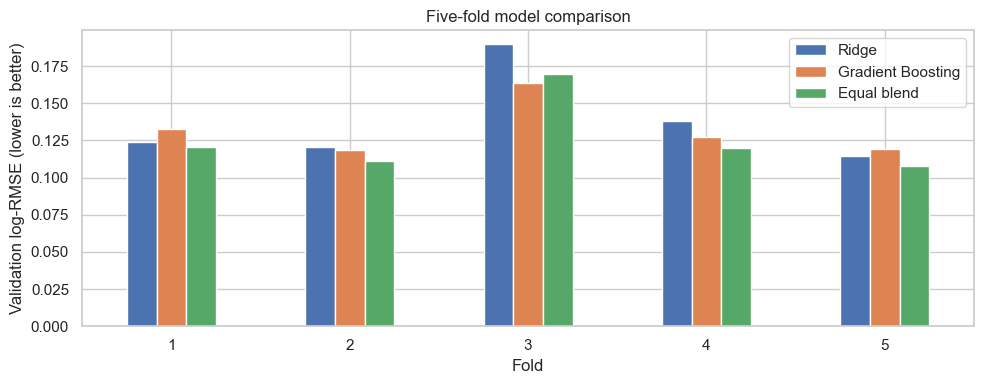

Ridge / Gradient Boosting OOF residual correlation: 0.752


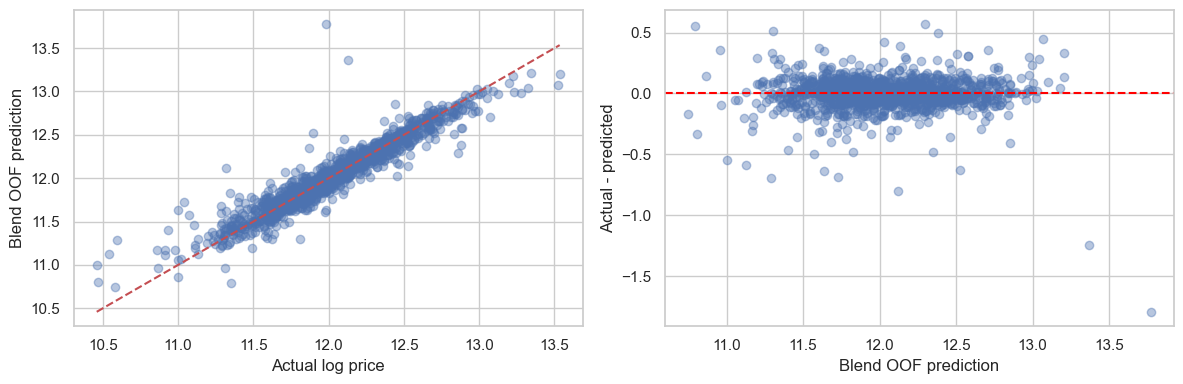

In [8]:
cv_results.set_index("Fold")[["Ridge", "Gradient Boosting", "Equal blend"]].plot(
    kind="bar", figsize=(10, 4)
)
plt.ylabel("Validation log-RMSE (lower is better)")
plt.title("Five-fold model comparison")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

residual_correlation = np.corrcoef(y - ridge_oof, y - gbr_oof)[0, 1]
print(f"Ridge / Gradient Boosting OOF residual correlation: {residual_correlation:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y, blend_oof, alpha=0.4)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
axes[0].set(xlabel="Actual log price", ylabel="Blend OOF prediction")
axes[1].scatter(blend_oof, y - blend_oof, alpha=0.4)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Blend OOF prediction", ylabel="Actual - predicted")
plt.tight_layout()
plt.show()


In [9]:
oof_results = pd.DataFrame({
    "Id": train["Id"],
    "Actual price": train["SalePrice"],
    "Ridge log prediction": ridge_oof,
    "GBR log prediction": gbr_oof,
    "Blend predicted price": np.exp(blend_oof),
    "Blend log residual": y - blend_oof,
    "Absolute log error": np.abs(y - blend_oof)
})
print(oof_results.nlargest(10, "Absolute log error").to_string(index=False))


  Id  Actual price  Ridge log prediction  GBR log prediction  Blend predicted price  Blend log residual  Absolute log error
1299        160000             14.187397           13.360151          959122.359602           -1.790845            1.790845
 524        184750             13.342174           13.390320          638097.678257           -1.239488            1.239488
 633         82500             12.107282           12.140192          184192.471116           -0.803183            0.803183
  31         40000             11.193513           11.381469           79816.943765           -0.690856            0.690856
 463         62383             11.733530           11.717936          123714.605234           -0.684685            0.684685
 411         60000             11.650642           11.625610          113337.597222           -0.636026            0.636026
1325        147000             12.534095           12.517085          275292.661337           -0.627402            0.627402
 969    

In [10]:
medians = X.median(numeric_only=True)
modes = X.select_dtypes(include="object").mode().iloc[0]
X_full = X.fillna(medians).fillna(modes)
X_test_full = X_test.fillna(medians).fillna(modes)

X_full = pd.get_dummies(X_full, dtype=int)
X_test_full = pd.get_dummies(X_test_full, dtype=int)
X_test_full = X_test_full.reindex(columns=X_full.columns, fill_value=0)

scaler = StandardScaler()
X_full_scaled = scaler.fit_transform(X_full)
X_test_scaled = scaler.transform(X_test_full)
assert np.isfinite(X_full_scaled).all() and np.isfinite(X_test_scaled).all()

final_ridge = Ridge(alpha=10)
final_ridge.fit(X_full_scaled, y)
ridge_test_pred = final_ridge.predict(X_test_scaled)
assert np.isfinite(final_ridge.coef_).all() and np.isfinite(ridge_test_pred).all()

final_gbr = GradientBoostingRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=2,
    min_samples_leaf=8, random_state=42
)
final_gbr.fit(X_full, y)
gbr_test_pred = final_gbr.predict(X_test_full)
assert np.isfinite(gbr_test_pred).all()

test_pred_log = 0.5 * ridge_test_pred + 0.5 * gbr_test_pred


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-p

In [12]:
submission = pd.DataFrame({"Id": test_ids, "SalePrice": np.exp(test_pred_log)})
assert len(submission) == len(test)
assert submission["Id"].is_unique
assert np.isfinite(submission["SalePrice"]).all() and (submission["SalePrice"] > 0).all()

submission.to_csv("/Users/songxiajinzhi/Desktop/DSAI4204/Proj/submission_v2.csv", index=False)
cv_results.to_csv("cv_results_v2.csv", index=False)
results.to_csv("model_comparison_v2.csv", index=False)
oof_results.to_csv("oof_predictions_v2.csv", index=False)

print("Model: 50% Ridge + 50% Gradient Boosting (log predictions)")
print(f"Five-fold OOF log-RMSE: {blend_score:.6f}")
print("Final training rows:", len(train))
print("Predicted test rows:", len(submission))
print("Submission file:", Path("submission_v2.csv").resolve())
submission.head()


Model: 50% Ridge + 50% Gradient Boosting (log predictions)
Five-fold OOF log-RMSE: 0.127864
Final training rows: 1460
Predicted test rows: 1459
Submission file: /Users/songxiajinzhi/Desktop/DSAI4204/Proj/submission_v2.csv


,Id,SalePrice
0,1461,118440.517835
1,1462,168975.576554
2,1463,184559.702666
3,1464,194442.863125
4,1465,195511.433784
